# Step 2: Explore the Support Conversations

**Project:** AI Customer Support Assistant (business analysis case study)

**Business question for this notebook:** What do customers contact support about, how much
work does each type of request take, and which requests involve sensitive steps like
identity checks or refunds?

**Data:** Action-Based Conversations Dataset (ABCD), ASAPP Research, 2021.
See `../data/README.md` for download instructions.

**Outputs** (saved to `outputs/`):
- `intent_summary.csv`: one row per request type, used in Step 4
- charts used in the README and the BRD

## 1. Setup and load the data

In [1]:
import gzip
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("..") / "data"
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Find the main conversations file (skip the small sample file)
candidates = sorted(
    p for p in DATA_DIR.glob("abcd*.json*") if "sample" not in p.name.lower()
)
print("Files found in data/:", [p.name for p in DATA_DIR.iterdir()])
if not candidates:
    raise FileNotFoundError(
        "No ABCD conversations file found in ../data. "
        "Copy the files from the cloned abcd repo's data/ folder."
    )
DATA_FILE = candidates[-1]
print("Using:", DATA_FILE.name)

def load_json(path):
    if path.suffix == ".gz":
        with gzip.open(path, "rt", encoding="utf-8") as f:
            return json.load(f)
    with open(path, encoding="utf-8") as f:
        return json.load(f)

raw = load_json(DATA_FILE)

Files found in data/: ['abcd_sample.json', 'abcd_v1.1.json', 'abcd_v1.1.json.gz', 'guidelines.json', 'images', 'kb.json', 'ontology.json', 'README.md', 'utterances.json']
Using: abcd_v1.1.json.gz


## 2. Look at the structure

Before analyzing anything, check how the file is organized. If anything printed here looks
different from what the code below expects, paste the output into the chat and we'll adjust.

In [2]:
print("Top-level type:", type(raw).__name__)

# The file is usually split into train / dev / test. Combine them all.
if isinstance(raw, dict):
    print("Top-level keys:", list(raw.keys()))
    convos = []
    for split, items in raw.items():
        for c in items:
            c["_split"] = split
            convos.append(c)
else:
    convos = raw

print("Total conversations:", len(convos))
first = convos[0]
print("\nKeys in one conversation:", list(first.keys()))
print("\nScenario keys:", list(first.get("scenario", {}).keys()))

Top-level type: dict
Top-level keys: ['train', 'dev', 'test']
Total conversations: 10042

Keys in one conversation: ['convo_id', 'scenario', 'original', 'delexed', '_split']

Scenario keys: ['personal', 'order', 'product', 'flow', 'subflow']


## 3. Read one conversation

In [3]:
def show_conversation(c, max_turns=40):
    sc = c.get("scenario", {})
    print(f"Conversation {c.get('convo_id')}  |  category: {sc.get('flow')}  |  request: {sc.get('subflow')}\n")
    for turn in c.get("original", [])[:max_turns]:
        speaker, text = turn[0], turn[1]
        print(f"{speaker.upper():>9}: {text}")

show_conversation(convos[0])

Conversation 3592  |  category: product_defect  |  request: return_size

    AGENT: Hi!
    AGENT: How can I help you?
 CUSTOMER: Hi! I need to return an item, can you help me with that?
    AGENT: sure, may I have your name please?
 CUSTOMER: Crystal Minh
    AGENT: thanks, may I ask the reason for the return?
   ACTION: Account has been pulled up for Crystal Minh.
 CUSTOMER: I got the wrong size.
    AGENT: ok, may I have your username, email address and order ID please?
 CUSTOMER: Username: cminh730
 CUSTOMER: cminh730@email.com
 CUSTOMER: Order ID: 3348917502
   ACTION: Purchase validation in progress ...
    AGENT: thanks so much! What is your membership level Crystal?
 CUSTOMER: I'm a bronze
    AGENT: ok, was the purchase made in the last 90 days?
 CUSTOMER: No, I bought it in November.
    AGENT: ok, unfortunately because it has been more than 90 days we cannot accept the return. Would there be anything else I can help you with?
 CUSTOMER: What if I ask really, really nicely?
 

## 4. Build one table: one row per conversation

- **category** (`flow`): the broad topic, for example orders or account access
- **request type** (`subflow`): the specific thing the customer wanted. This is the
  "intent", and the dataset has 55 of them.
- **turns**: messages from the customer, messages from the agent, and system actions the
  agent took (such as pulling up an account)

In [4]:
def action_names(c):
    """Names of the system actions the agent took in this conversation."""
    names = []
    for t in c.get("delexed", []):
        if t.get("speaker") == "action":
            targets = t.get("targets") or []
            if len(targets) >= 3 and targets[2]:
                names.append(targets[2])
    return names

rows = []
for c in convos:
    sc = c.get("scenario", {})
    turns = c.get("original", [])
    speakers = [t[0] for t in turns]
    rows.append({
        "convo_id": c.get("convo_id"),
        "split": c.get("_split"),
        "category": sc.get("flow"),
        "request_type": sc.get("subflow"),
        "total_turns": len(turns),
        "customer_turns": speakers.count("customer"),
        "agent_turns": speakers.count("agent"),
        "action_turns": speakers.count("action"),
        "actions": action_names(c),
    })

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(10042, 9)


,convo_id,split,category,request_type,total_turns,customer_turns,agent_turns,action_turns,actions
0,3592,train,product_defect,return_size,29,13,12,4,"[pull-up-account, validate-purchase, enter-det..."
1,9489,train,product_defect,refund_status,21,10,9,2,"[pull-up-account, validate-purchase]"
2,3695,train,storewide_query,timing_4,22,8,11,3,"[search-faq, search-timing, select-faq]"
3,5798,train,shipping_issue,manage,23,7,12,4,"[pull-up-account, shipping-status, validate-pu..."
4,3647,train,storewide_query,pricing_3,23,13,7,3,"[search-faq, search-pricing, select-faq]"


## 5. The big picture

In [5]:
print(f"Conversations:   {len(df):,}")
print(f"Categories:      {df['category'].nunique()}")
print(f"Request types:   {df['request_type'].nunique()}")
print(f"Median length:   {df['total_turns'].median():.0f} turns")
print(f"Median actions:  {df['action_turns'].median():.0f} per conversation")

# Does the data include timestamps? (Needed to know whether handle time is measurable.)
time_keys = [k for k in first.keys() if "time" in k.lower()]
print("\nTime-related fields:", time_keys or "none, so handle time will be an assumption")

Conversations:   10,042
Categories:      10
Request types:   96
Median length:   21 turns
Median actions:  3 per conversation

Time-related fields: none, so handle time will be an assumption


## 6. What do customers contact support about?

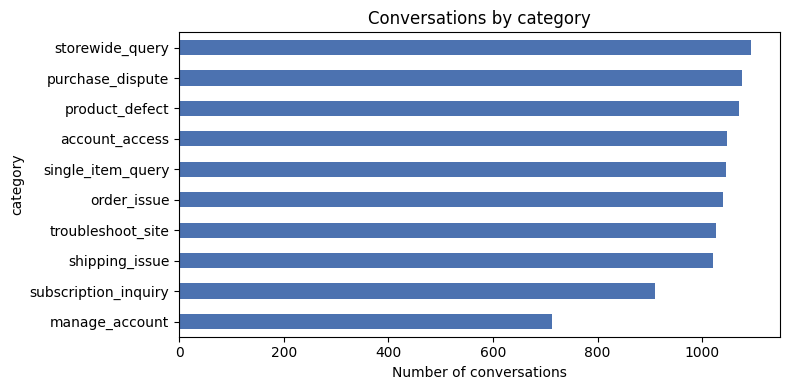

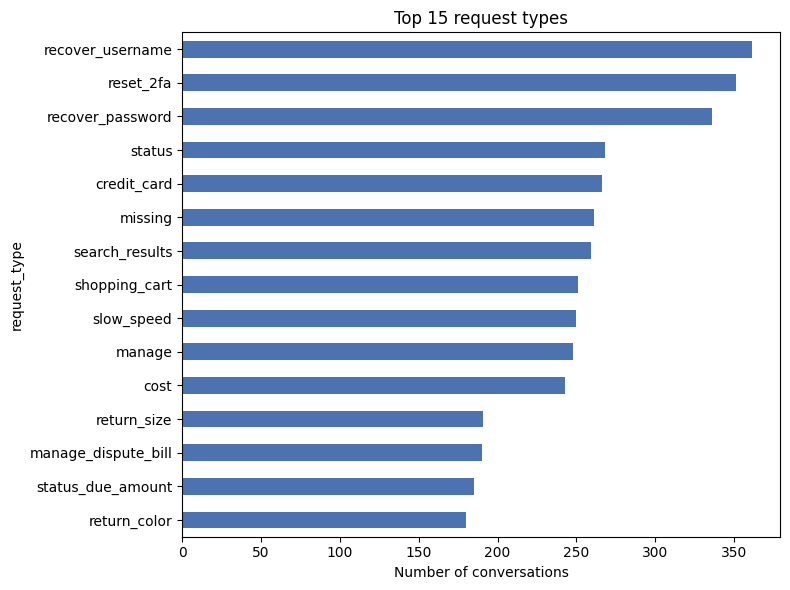

Top 5 request types make up 16% of conversations
Top 10 request types make up 28% of conversations


In [6]:
by_category = df["category"].value_counts()
ax = by_category.sort_values().plot(kind="barh", figsize=(8, 4), color="#4C72B0")
ax.set_title("Conversations by category")
ax.set_xlabel("Number of conversations")
plt.tight_layout()
plt.savefig(OUT_DIR / "conversations_by_category.png", dpi=150)
plt.show()

by_request = df["request_type"].value_counts()
top15 = by_request.head(15)
ax = top15.sort_values().plot(kind="barh", figsize=(8, 6), color="#4C72B0")
ax.set_title("Top 15 request types")
ax.set_xlabel("Number of conversations")
plt.tight_layout()
plt.savefig(OUT_DIR / "top_request_types.png", dpi=150)
plt.show()

share = by_request / by_request.sum()
print(f"Top 5 request types make up {share.head(5).sum():.0%} of conversations")
print(f"Top 10 request types make up {share.head(10).sum():.0%} of conversations")

## 7. How much work does each request take?

Longer conversations with more actions cost more agent time, so they're more valuable to
automate. They're also usually harder for AI to get right.

In [7]:
effort = (
    df.groupby("request_type")
      .agg(conversations=("convo_id", "count"),
           median_turns=("total_turns", "median"),
           median_customer_turns=("customer_turns", "median"),
           median_actions=("action_turns", "median"))
      .sort_values("conversations", ascending=False)
)
effort.head(15)

,conversations,median_turns,median_customer_turns,median_actions
request_type,,,,
recover_username,361,17.0,7.0,2.0
reset_2fa,351,19.0,7.0,3.0
recover_password,336,21.0,8.0,3.0
status,268,25.0,10.0,4.0
credit_card,266,19.0,8.0,3.0
missing,261,26.0,11.0,5.0
search_results,259,20.0,8.0,2.0
shopping_cart,251,18.0,7.0,2.0
slow_speed,250,20.0,8.0,3.0


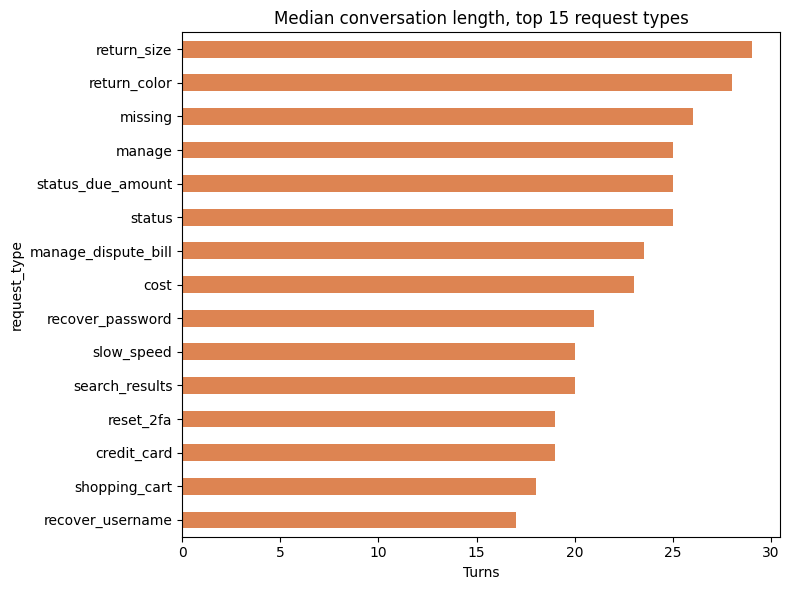

In [8]:
ax = effort.head(15)["median_turns"].sort_values().plot(kind="barh", figsize=(8, 6), color="#DD8452")
ax.set_title("Median conversation length, top 15 request types")
ax.set_xlabel("Turns")
plt.tight_layout()
plt.savefig(OUT_DIR / "length_by_request_type.png", dpi=150)
plt.show()

## 8. Which actions do agents take?

In [9]:
action_counts = Counter(a for acts in df["actions"] for a in set(acts))
actions_df = (pd.DataFrame(action_counts.items(), columns=["action", "conversations"])
                .sort_values("conversations", ascending=False))
actions_df["share_of_all_conversations"] = (actions_df["conversations"] / len(df)).round(3)
actions_df

,action,conversations,share_of_all_conversations
3,pull-up-account,6936,0.691
11,verify-identity,3379,0.336
5,search-faq,2341,0.233
1,validate-purchase,2273,0.226
0,enter-details,2005,0.200
20,ask-the-oracle,1696,0.169
6,select-faq,1579,0.157
21,record-reason,1546,0.154
8,update-order,1512,0.151
10,membership,1371,0.137


## 9. Group the actions by risk (for Step 4)

Each of the 30 agent actions goes into one group, based on what it does and how risky it
would be to let AI do it. Groups with an asterisk need a human or a strong safeguard.

| Group | What it means |
|---|---|
| general_info | Looking up public information: FAQs, policies, prices, product details |
| account_lookup | Opening the customer's account or reading their order and membership status |
| identity_verification* | Confirming the customer is who they say they are |
| record_change* | Changing an order, account or password |
| money* | Refunds, promo codes, purchases |
| troubleshooting | Guided fixes like "log out and back in" or "try again" |
| handoff_or_logging | Passing the case to another team or recording why the customer called |

A few actions have unclear names. Use `show_example("action-name")` in the next cell to
read a real conversation with that action and check the grouping.

In [10]:
ACTION_GROUPS = {
    "general_info": ["search-faq", "select-faq", "search-policy", "search-pricing",
                     "search-timing", "search-membership", "search-boots", "search-jacket",
                     "search-jeans", "search-shirt", "instructions", "send-link"],
    "account_lookup": ["pull-up-account", "shipping-status", "subscription-status",
                       "membership"],
    "identity_verification": ["verify-identity", "validate-purchase"],
        "record_change": ["update-order", "update-account", "make-password", "enter-details"],
    "money": ["offer-refund", "promo-code", "make-purchase"],
    "troubleshooting": ["try-again", "log-out-in", "ask-the-oracle"],
    "handoff_or_logging": ["notify-team", "record-reason"],
}
ACTION_TO_GROUP = {a: g for g, acts in ACTION_GROUPS.items() for a in acts}

# Check that every action in the data has a group
unmapped = sorted(set(actions_df["action"]) - set(ACTION_TO_GROUP))
print("Actions without a group:", unmapped or "none")

def show_example(action, n_turns=30):
    """Print the first conversation that contains this action."""
    for c in convos:
        if action in action_names(c):
            show_conversation(c, max_turns=n_turns)
            return
    print("No conversation found with", action)

show_example("enter-details")   # remove the # to read an example

Actions without a group: none
Conversation 3592  |  category: product_defect  |  request: return_size

    AGENT: Hi!
    AGENT: How can I help you?
 CUSTOMER: Hi! I need to return an item, can you help me with that?
    AGENT: sure, may I have your name please?
 CUSTOMER: Crystal Minh
    AGENT: thanks, may I ask the reason for the return?
   ACTION: Account has been pulled up for Crystal Minh.
 CUSTOMER: I got the wrong size.
    AGENT: ok, may I have your username, email address and order ID please?
 CUSTOMER: Username: cminh730
 CUSTOMER: cminh730@email.com
 CUSTOMER: Order ID: 3348917502
   ACTION: Purchase validation in progress ...
    AGENT: thanks so much! What is your membership level Crystal?
 CUSTOMER: I'm a bronze
    AGENT: ok, was the purchase made in the last 90 days?
 CUSTOMER: No, I bought it in November.
    AGENT: ok, unfortunately because it has been more than 90 days we cannot accept the return. Would there be anything else I can help you with?
 CUSTOMER: What if 

In [11]:
def groups_in(actions):
    return {ACTION_TO_GROUP.get(a, "unmapped") for a in actions}

df["action_groups"] = df["actions"].apply(groups_in)
for g in ACTION_GROUPS:
    df[f"has_{g}"] = df["action_groups"].apply(lambda s, g=g: g in s)

# Information only: every action is a general_info lookup (or there are no actions)
df["info_only"] = df["action_groups"].apply(lambda s: s <= {"general_info"})

flag_cols = [f"has_{g}" for g in ACTION_GROUPS] + ["info_only"]
flags = df.groupby("request_type")[flag_cols].mean().round(2)
summary = effort.join(flags)

def common_actions(series, n=4):
    counts = Counter(a for acts in series for a in set(acts))
    return ", ".join(a for a, _ in counts.most_common(n))

summary["most_common_actions"] = df.groupby("request_type")["actions"].apply(common_actions)
summary["share_of_volume"] = (summary["conversations"] / summary["conversations"].sum()).round(3)
summary.head(15)

,conversations,median_turns,median_customer_turns,median_actions,has_general_info,has_account_lookup,has_identity_verification,has_record_change,has_money,has_troubleshooting,has_handoff_or_logging,info_only,most_common_actions,share_of_volume
request_type,,,,,,,,,,,,,,
recover_username,361,17.0,7.0,2.0,0.01,0.98,0.98,0.04,0.00,0.01,0.02,0.01,"pull-up-account, verify-identity, enter-detail...",0.036
reset_2fa,351,19.0,7.0,3.0,0.85,0.97,0.08,0.97,0.01,0.01,0.03,0.00,"pull-up-account, enter-details, send-link, ver...",0.035
recover_password,336,21.0,8.0,3.0,0.02,0.97,0.31,0.99,0.01,0.00,0.00,0.00,"pull-up-account, make-password, enter-details,...",0.033
status,268,25.0,10.0,4.0,0.05,0.96,0.97,0.46,0.04,0.85,0.04,0.01,"pull-up-account, verify-identity, ask-the-orac...",0.027
credit_card,266,19.0,8.0,3.0,0.08,0.14,0.02,0.58,0.14,0.97,0.00,0.00,"log-out-in, try-again, enter-details, pull-up-...",0.026
missing,261,26.0,11.0,5.0,0.02,0.97,0.98,0.60,0.56,0.15,0.69,0.01,"pull-up-account, validate-purchase, record-rea...",0.026
search_results,259,20.0,8.0,2.0,0.76,0.11,0.02,0.02,0.05,0.93,0.26,0.03,"log-out-in, instructions, try-again, notify-team",0.026
shopping_cart,251,18.0,7.0,2.0,0.11,0.12,0.01,0.37,0.07,0.98,0.01,0.00,"log-out-in, try-again, enter-details, pull-up-...",0.025
slow_speed,250,20.0,8.0,3.0,0.64,0.02,0.00,0.02,0.06,0.96,0.50,0.00,"log-out-in, try-again, instructions, notify-team",0.025


## 10. Save the summary for Step 4

In [12]:
summary.to_csv(OUT_DIR / "intent_summary.csv")
print("Saved", OUT_DIR / "intent_summary.csv", "with", len(summary), "request types")

Saved outputs\intent_summary.csv with 96 request types


## 11. Key findings (auto-generated draft)

In [13]:
top5 = share.head(5)
pct = lambda col: f"{df[col].mean():.0%}"
print("KEY FINDINGS (draft, check before using in the README)\n")
print(f"1. {len(df):,} conversations across {df['request_type'].nunique()} request types "
      f"in {df['category'].nunique()} categories.")
print(f"2. The top 5 request types make up {top5.sum():.0%} of volume: "
      + ", ".join(f"{k} ({v:.0%})" for k, v in top5.items()) + ".")
print(f"3. {pct('has_account_lookup')} of conversations need access to the customer's account or order.")
print(f"4. {pct('has_identity_verification')} require confirming the customer's identity.")
print(f"5. {pct('has_record_change')} change an order, account or password.")
print(f"6. {pct('has_money')} involve money (refunds, promo codes, purchases).")
print(f"7. {pct('has_handoff_or_logging')} include a handoff to another team or a logged reason.")
print(f"8. {pct('info_only')} need only general information, making them the safest "
      "starting point for automation.")

KEY FINDINGS (draft, check before using in the README)

1. 10,042 conversations across 96 request types in 10 categories.
2. The top 5 request types make up 16% of volume: recover_username (4%), reset_2fa (3%), recover_password (3%), status (3%), credit_card (3%).
3. 70% of conversations need access to the customer's account or order.
4. 52% require confirming the customer's identity.
5. 35% change an order, account or password.
6. 18% involve money (refunds, promo codes, purchases).
7. 19% include a handoff to another team or a logged reason.
8. 19% need only general information, making them the safest starting point for automation.


In [14]:
# Is there a broader request label inside the conversations?
convo_intents = []
for c in convos:
    labels = {(t.get("targets") or [None])[0] for t in c.get("delexed", [])}
    labels.discard(None); labels.discard("")
    convo_intents.append(labels)

df["intent_labels"] = convo_intents
all_labels = Counter(l for s in convo_intents for l in s)
print("Unique labels:", len(all_labels))
print("Labels per conversation:", Counter(len(s) for s in convo_intents))
print(all_labels.most_common(10))

Unique labels: 55
Labels per conversation: Counter({1: 10042})
[('recover_username', 361), ('reset_2fa', 351), ('recover_password', 336), ('membership', 281), ('boots', 281), ('pricing', 277), ('policy', 272), ('status', 268), ('credit_card', 266), ('timing', 264)]
